# Radar simulation with OSI interfaces

The radar simulation as **modules connected only by OSI messages**.

In [13]:
import matplotlib.pyplot as plt

from osi_hfss import modules
from osi_hfss.data import load
from osi_hfss.analysis import detection_table, expected_positions
from osi_hfss.messages import describe
from osi_hfss.plots import plot_detections

## Front radar: FMCW, TDM-MIMO, highway

The inputs come from `data/`; every module runs on them or on the output of the previous module (each call
serializes its inputs, runs the module executable in `bin/` and parses its output message).

In [14]:
# Inputs
ground_truth, configuration = load("front.groundtruth.bin"), load("front.sensorviewconfiguration.bin")
scene, antenna_config, generator_config = load("front.scene.json"), load("front.antenna.json"), load("front.signal_generator.json")

# Modules, chained
sensor_view = modules.environment_simulation(ground_truth, configuration, scene)  # -> SensorView
antenna = modules.antenna_model(antenna_config)  # -> AntennaModel
cpi = modules.fmcw_signal_generator(sensor_view, antenna, generator_config)  # SensorView + AntennaModel -> RadarCpiData
sensor_data = modules.radar_dsp(cpi, antenna)  # RadarCpiData + AntennaModel -> SensorData

In [15]:
for message in (sensor_view, antenna, cpi, sensor_data):
    print(f"{type(message).__name__:16s} {describe(message)}")

SensorView       9 reflections at 76.75 GHz, 5 objects in the ground truth
AntennaModel     7 elements, 7 element types (embedded patterns)
RadarCpiData     1 CPI frame, 12 channels KIND_VIRTUAL, 64 x 256 cells (DOMAIN_SLOW_TIME x DOMAIN_RANGE)
SensorData       3 radar detections


## Corner radar: PMCW, CDM-MIMO, urban

A very different radar behind the same interfaces: another scene and antenna, another signal generator
module, the same DSP module.

In [16]:
corner_sensor_view = modules.environment_simulation(
    load("corner.groundtruth.bin"), load("corner.sensorviewconfiguration.bin"), load("corner.scene.json"))
corner_antenna = modules.antenna_model(load("corner.antenna.json"))
corner_cpi = modules.pmcw_signal_generator(corner_sensor_view, corner_antenna, load("corner.signal_generator.json"))
corner_sensor_data = modules.radar_dsp(corner_cpi, corner_antenna)

## Detections and their expected positions

front radar (FMCW)
      object | detected: range [m] az [deg] v_r [m/s] SNR [dB] | expected: range [m] az [deg] v_r [m/s]
           3 |               22.13    33.00     16.95     48.5 |               22.05    32.97     16.78
           2 |               56.91     5.50     -4.75     43.3 |               56.77     5.56     -4.98
           1 |               33.02   -27.00      4.75     42.9 |               33.09   -26.95      4.46

corner radar (PMCW)
      object | detected: range [m] az [deg] v_r [m/s] SNR [dB] | expected: range [m] az [deg] v_r [m/s]
           1 |                9.14   -21.75      7.25     79.4 |                9.14   -21.80      7.35
           2 |                9.59     3.00      6.34     63.1 |                9.56     2.97      6.40
           4 |               19.64    32.00      7.70     60.6 |               19.60    32.03      7.64
           3 |               19.79   -11.00      2.49     57.9 |               19.80   -10.91      2.48
           5 |          

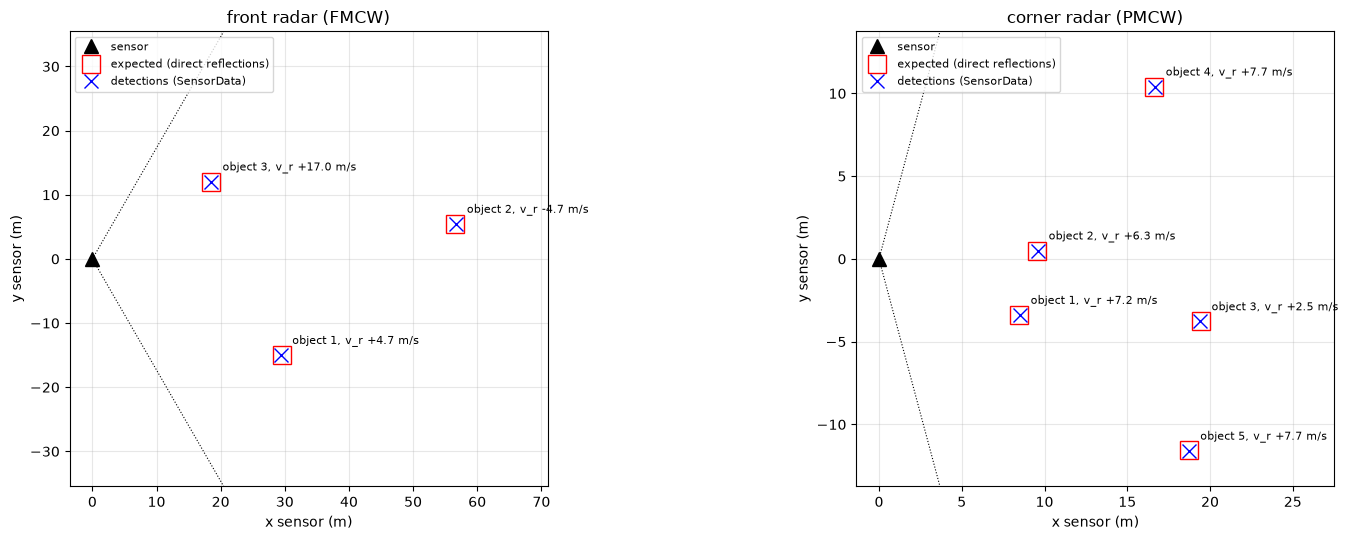

In [17]:
radars = {"front radar (FMCW)": (sensor_view, sensor_data), "corner radar (PMCW)": (corner_sensor_view, corner_sensor_data)}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, (title, (radar_sensor_view, radar_sensor_data)) in zip(axes, radars.items()):
    expected = expected_positions(radar_sensor_view)
    print(f"{title}\n{detection_table(radar_sensor_data, expected)}\n")
    plot_detections(radar_sensor_data, expected, radar_sensor_view.radar_sensor_view[0].view_configuration.field_of_view_horizontal, title, ax=ax)
plt.tight_layout(); plt.show()